# ЛР09. Промпт-инжиниринг

**Вариант 7:** контекст 2 — обложка подкаста о городе; элемент 1 — стилевая фраза `minimal flat geometric style`; seed 101…105.

## Гипотезы и допуск — зафиксированы до запуска (06.11.2026 16:35)

**Часть 1.** H1: `clip_target` вырастет сильнее разброса между seed (Δ > 2s) и больше допуска 1,0. H2: `clip_subject` не упадёт больше допуска 1,0. H3: `edge` вырастет больше чем на 10 %, `contrast` изменится в пределах ±10 %. H4: на изображениях B слои горизонта читаются как отдельные полосы чаще, чем на A.

**Часть 2.** H5: все три приёма дадут K1, K2, K3 не ниже 0,8. H6: наибольшая стабильность K4 у few-shot, наименьшая — у пошаговых инструкций.

**Допуск.** `clip_target`, `clip_subject` — 1,0 пункта; `edge`, `contrast` — 10 % от режима A.

Вывод делается только после измерения и только для проверенных условий.

In [1]:
# Исправление среды Colab до импорта diffusers: предустановленный torchao несовместим с diffusers (как в ЛР06). SD Turbo и CLIP torchao не используют.
!pip uninstall -y -q torchao

import importlib.util
assert importlib.util.find_spec("torchao") is None, "torchao не удалён: перезапустите сеанс и выполните ячейку снова"
ENVIRONMENT_FIXES = ["torchao uninstalled before importing diffusers: incompatible with the installed diffusers"]
print("torchao удалён")

torchao удалён


In [2]:
# Фактические версии. Библиотека считает на процессоре, GPU для этой работы не нужен.
!pip list 2>/dev/null | grep -i -E "^(torch|diffusers|transformers|numpy|scipy|pillow|pandas) "

import json, pathlib, platform, shutil, sys, time
from datetime import datetime, timezone
import numpy as np, scipy, torch, diffusers, transformers, PIL

environment = {
    "execution_environment": "Google Colab",
    "device": "cpu",
    "cuda_available": torch.cuda.is_available(),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "packages": {"torch": torch.__version__, "diffusers": diffusers.__version__, "transformers": transformers.__version__,
                 "numpy": np.__version__, "scipy": scipy.__version__, "pillow": PIL.__version__},
    "environment_fixes": ENVIRONMENT_FIXES,
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
}
print(json.dumps(environment, ensure_ascii=False, indent=2))

diffusers                             0.42.1
numpy                                 2.4.6
pandas                                2.2.3
pillow                                11.3.0
scipy                                 1.16.3
torch                                 2.11.0+cpu
transformers                          5.22.0
{
  "execution_environment": "Google Colab",
  "device": "cpu",
  "cuda_available": false,
  "python": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "packages": {
    "torch": "2.11.0+cpu",
    "diffusers": "0.42.1",
    "transformers": "5.22.0",
    "numpy": "2.4.6",
    "scipy": "1.16.3",
    "pillow": "11.3.0"
  },
  "environment_fixes": [
    "torchao uninstalled before importing diffusers: incompatible with the installed diffusers"
  ],
  "started_at_utc": "2026-11-06T14:13:06.997154+00:00"
}


In [3]:
%%writefile lab09_lib.py
# ЛР 9. Промпт-инжиниринг, часть 1: контролируемое сравнение запросов для SD Turbo. Библиотека учебных функций.
# Проверено 20.09.2026: Engee 26.8.2-H3, процессор, Python 3.11, torch 2.4.1+cu121, diffusers 0.32.2, transformers 4.57.6.
# Установка (один раз):  pip install "diffusers==0.32.2" "transformers<5"   (новые версии не работают с torch 2.4.1)
import time
import numpy as np
import torch
from scipy import ndimage
from diffusers import StableDiffusionPipeline
from transformers import CLIPModel, CLIPProcessor

torch.set_num_threads(min(4, torch.get_num_threads()))
MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"
# CLIP ViT-B/32 из ЛР 6 не годится: его веса лежат только в pickle-файле, а transformers запрещает torch.load при torch < 2.6 (CVE-2025-32434).
# Берём CLIP ViT-L/14 того же автора (OpenAI): у него есть model.safetensors. Числа ЛР 9 несопоставимы с ЛР 6 по абсолютной величине.
CLIP_ID = "openai/clip-vit-large-patch14"
CLIP_REVISION = "32bd64288804d66eefd0ccbe215aa642df71cc41"
SEEDS = range(101, 106)          # серия seed
STEPS, GUIDANCE, SIZE = 1, 0.0, 512   # рекомендованный режим SD Turbo (лекция 4)

# Пять контекстов: базовый запрос A — только предмет (как в ЛР 6).
SHORT = ["robotic arm poster", "podcast cover about the city", "science exhibition poster",
         "ecology lecture visual, forest", "electronic music cover art"]
FACTORS = ["style", "light", "palette", "composition", "boilerplate", "negation"]
BOILER = "masterpiece, best quality, highly detailed, 8k"
# ELEMENTS[c][k] = (добавляемая фраза, текст-цель для CLIP). Запрос B = A + ", " + фраза.
ELEMENTS = [
    [("flat vector illustration",) * 2, ("dramatic rim light",) * 2, ("deep blue and amber colors",) * 2,
     ("centered composition with empty space around",) * 2, (BOILER, "highly detailed, sharp, high quality image"), ("no people, no text", "a person")],
    [("minimal flat geometric style",) * 2, ("warm sunset light",) * 2, ("teal and orange colors",) * 2,
     ("symmetrical layered horizon",) * 2, (BOILER, "highly detailed, sharp, high quality image"), ("no people, no text", "a person")],
    [("isometric 3D render",) * 2, ("soft glow",) * 2, ("dark background with white and cyan lines",) * 2,
     ("balanced constellation of connected nodes",) * 2, (BOILER, "highly detailed, sharp, high quality image"), ("no logo, no text", "written text and letters")],
    [("watercolor illustration",) * 2, ("soft morning light",) * 2, ("green and gold colors",) * 2,
     ("top-down view from above",) * 2, (BOILER, "highly detailed, sharp, high quality image"), ("no people, no text", "a person")],
    [("macro photography",) * 2, ("neon rim light",) * 2, ("iridescent purple and cyan colors",) * 2,
     ("close-up with strong contrast",) * 2, (BOILER, "highly detailed, sharp, high quality image"), ("no logo, no text", "written text and letters")],
]
METRICS = ("clip_target", "clip_subject", "edge", "contrast")


def load_pipe():
    """Закреплённая ревизия, float32, процессор. Предупреждение о safety_checker ожидаемо: у SD Turbo его нет."""
    pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, revision=REVISION, torch_dtype=torch.float32,
                                                   safety_checker=None, requires_safety_checker=False)
    pipe.set_progress_bar_config(disable=True)
    return pipe


def load_clip():
    model = CLIPModel.from_pretrained(CLIP_ID, revision=CLIP_REVISION, use_safetensors=True).eval()
    proc = CLIPProcessor.from_pretrained(CLIP_ID, revision=CLIP_REVISION)
    return model, proc


def generate(pipe, prompt, seed):
    g = torch.Generator("cpu").manual_seed(seed)
    return pipe(prompt, num_inference_steps=STEPS, guidance_scale=GUIDANCE, height=SIZE, width=SIZE, generator=g).images[0]


@torch.no_grad()
def clip_sims(clip, img, texts):
    """Косинусное сходство изображения с каждым текстом в CLIP, умноженное на 100 (не CLIPScore)."""
    model, proc = clip
    inp = proc(text=list(texts), images=img, return_tensors="pt", padding=True, truncation=True)
    out = model(**inp)
    a = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    b = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return [float(v) * 100 for v in (a @ b.T)[0]]


def luma(img):
    x = np.asarray(img.convert("RGB"), dtype=np.float64) / 255
    return 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]


def edge_energy(img):
    """Средняя длина градиента яркости (Собель, нормировка 1/8), как в ЛР 4 и ЛР 6."""
    y = luma(img)
    return float(np.mean(np.hypot(ndimage.sobel(y, axis=0), ndimage.sobel(y, axis=1)) / 8))


def contrast(img):
    return float(np.std(luma(img)))


def texts_for(c):
    """Тексты для CLIP по контексту c: предмет и шесть целей факторов."""
    return [SHORT[c]] + [ELEMENTS[c][k][1] for k in range(6)]


def prompt_a(c):
    return SHORT[c]


def prompt_b(c, k):
    return SHORT[c] + ", " + ELEMENTS[c][k][0]


def measure(pipe, clip, c, prompt, seed):
    """Одно изображение: метрики (сходство с предметом и со всеми шестью целями, энергия границ, контраст) и время, с."""
    t0 = time.perf_counter()
    img = generate(pipe, prompt, seed)
    dt = time.perf_counter() - t0
    sims = clip_sims(clip, img, texts_for(c))
    return dict(sims=sims, edge=edge_energy(img), contrast=contrast(img), seconds=dt), img


def compare(a_list, b_list, k):
    """Сводка по четырём метрикам: A, s (по seed режима A), B, разность, |d|/s, признак |d| > 2s. a_list, b_list — результаты measure()."""
    rows = []
    for m in METRICS:
        pick = {"clip_target": lambda r: r["sims"][1 + k], "clip_subject": lambda r: r["sims"][0],
                "edge": lambda r: r["edge"], "contrast": lambda r: r["contrast"]}[m]
        A = [pick(r) for r in a_list]; B = [pick(r) for r in b_list]
        d = float(np.mean(B) - np.mean(A)); s = float(np.std(A, ddof=1))
        rows.append((m, float(np.mean(A)), s, float(np.mean(B)), d, abs(d) / s if s > 0 else float("inf"), bool(abs(d) > 2 * s)))
    return rows


def variant_summary(pipe, clip, n, seeds=SEEDS):
    """Вариант n = 1..30: контекст c = (n-1)//6, фактор k = (n-1)%6. Режим A — только предмет, режим B — предмет плюс одна фраза."""
    c, k = (n - 1) // 6, (n - 1) % 6
    generate(pipe, prompt_a(c), 0)      # прогрев
    a = [measure(pipe, clip, c, prompt_a(c), s)[0] for s in seeds]
    b = [measure(pipe, clip, c, prompt_b(c, k), s)[0] for s in seeds]
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=compare(a, b, k))


Writing lab09_lib.py


In [4]:
%%writefile lab09_llm.py
# ЛР 9, часть 2: языковая модель как звено конвейера. Запросы, проверка схемы и покрытие смысловых элементов брифа.
# Только стандартная библиотека Python 3: работает в Engee, на ноутбуке и в Colab. Языковая модель — любой чат (в демонстрации — веб-версия Perplexity):
# запрос копируется в новый чат, ответ сохраняется в файл ответа целиком (текстом), файл проверяется score_file().
import json, re, sys

STYLES = ["flat vector illustration", "photorealistic", "3D render", "watercolor", "minimal geometric", "macro photography", "pencil sketch", "isometric 3D render"]
COMPOSITIONS = ["centered", "rule of thirds", "symmetrical", "top-down", "close-up", "wide negative space"]
PALETTE = ["blue", "amber", "orange", "teal", "green", "red", "pink", "purple", "yellow", "gray", "black", "white"]
AVOID = ["people", "text", "logo", "watermark", "blur"]
KEYS = ["subject", "setting", "style", "lighting", "palette", "composition", "avoid"]
# Какие запреты (avoid) содержит описание заказчика: ключ — (контекст, номер описания с 0); остальные описания запретов не содержат.
AVOID_EXPECTED = {(1, 0): ["people", "text"], (2, 2): ["people"], (3, 0): ["logo"], (4, 4): ["text"], (5, 0): ["logo"]}

# Пять контекстов по пять описаний заказчика. concepts — группы подстрок (латиница, нижний регистр): элемент брифа считается переданным,
# если в тексте JSON-объекта найдена хотя бы одна подстрока группы.
BRIEFS = {
    1: [
        ("Нужен плакат для фестиваля робототехники: светящаяся механическая рука в синих и янтарных тонах, без людей и текста.",
         [["arm", "hand"], ["glow", "lumin", "light"], ["blue"], ["amber", "orange"]]),
        ("Афиша соревнований роботов-манипуляторов: строгий индустриальный стиль, холодный свет, но только не синий; много пустого места для заголовка.",
         [["manipulator", "robot", "arm"], ["industrial", "technical"], ["cold", "cool", "white", "gray"], ["negative space", "empty"], ["!blue"]]),
        ("Обложка буклета школьного кружка робототехники: дружелюбный маленький робот на столе, тёплый свет лампы.",
         [["robot"], ["friendly", "cute", "small"], ["desk", "table"], ["warm", "lamp"]]),
        ("Баннер для сайта фестиваля: рука-манипулятор берёт светящийся шар, вид крупным планом; палитра — ровно два цвета: чёрный и электрический синий.",
         [["arm", "manipulator", "robot"], ["sphere", "ball", "orb"], ["glow", "lumin"], ["close-up", "close up"], ["black"], ["blue"], ["=2"]]),
        ("Иллюстрация к статье об автоматизации склада: ряды стеллажей и робот-погрузчик, изометрия, серо-оранжевая гамма.",
         [["warehouse", "shelv", "rack"], ["robot", "forklift", "loader"], ["isometric"], ["gray", "grey"], ["orange"]]),
    ],
    2: [
        ("Обложка подкаста о городе: слоистый горизонт из геометрических фигур, бирюзовый и оранжевый цвета, минимализм, квадратный формат.",
         [["skyline", "horizon", "city"], ["geometric"], ["teal", "turquoise"], ["orange"], ["minimal", "flat"]]),
        ("Обложка выпуска про ночной город: тёмное небо, огни окон, вид с крыши; оранжевого и янтарного в палитре быть не должно.",
         [["night", "dark"], ["window", "lights"], ["rooftop", "roof"], ["city"], ["!orange", "!amber"]]),
        ("Обложка выпуска о велодорожках и общественном транспорте: яркая плоская иллюстрация, без людей.",
         [["bicycle", "bike", "tram", "bus", "transport"], ["flat"], ["bright", "vivid", "colorful"]]),
        ("Обложка выпуска о дворах и зелёных крышах: вид сверху, тёплое утро; палитра — ровно два цвета: зелёный и жёлтый.",
         [["courtyard", "yard", "green roof", "rooftop"], ["top-down", "aerial", "above"], ["morning", "sunrise", "warm"], ["green"], ["yellow"], ["=2"]]),
        ("Обложка выпуска о старом районе: кирпичные фасады, закатный свет, акварель.",
         [["brick"], ["facade", "building"], ["sunset", "golden", "warm"], ["watercolor"]]),
    ],
    3: [
        ("Плакат научной выставки: созвездие соединённых узлов, тёмный фон, белые и голубые линии, без логотипов.",
         [["constellation", "node", "network"], ["connect", "line"], ["dark", "black"], ["white"], ["cyan", "light blue", "blue"]]),
        ("Афиша выставки о микромире: крупные кристаллы под микроскопом, холодная гамма, красного и оранжевого не использовать.",
         [["crystal"], ["microscop", "micro", "macro"], ["cold", "cool", "blue"], ["!red", "!orange"]]),
        ("Плакат о космосе: туманность и одинокий зонд, глубокий синий цвет, симметрия.",
         [["nebula"], ["probe", "spacecraft", "satellite"], ["blue"], ["symmetr"]]),
        ("Обложка каталога выставки: абстрактная спираль ДНК, светящиеся линии на тёмном фоне; цветов в палитре ровно три: голубой, фиолетовый, белый.",
         [["dna", "helix", "spiral"], ["glow", "lumin"], ["dark", "black"], ["blue"], ["purple"], ["white"], ["=3"]]),
        ("Постер об энергетике будущего: солнечные панели и ветряки на закате, широкая композиция.",
         [["solar", "panel"], ["wind", "turbine"], ["sunset"], ["wide", "panoram", "negative space"]]),
    ],
    4: [
        ("Визуал к лекциям по экологии: вид сверху на лес, слоистые зелёные формы, мягкий утренний свет.",
         [["forest", "canopy", "tree"], ["top-down", "above", "aerial"], ["green"], ["soft"], ["morning"]]),
        ("Слайд о загрязнении рек: чистая и мутная вода рядом, симметричная композиция, акварель, зелёного в палитре нет.",
         [["river", "water"], ["clean", "clear"], ["murky", "pollut", "dirty", "turbid"], ["symmetr"], ["watercolor"], ["!green"]]),
        ("Лекция о пчёлах и опылителях: пчела на цветке, макросъёмка, тёплый свет.",
         [["bee"], ["flower"], ["macro", "close-up"], ["warm"]]),
        ("Обложка курса о климате: тающий ледник, широкий план; палитра — ровно два цвета: синий и белый.",
         [["glacier", "ice"], ["melt"], ["wide", "panoram"], ["blue"], ["white"], ["=2"]]),
        ("Заставка о переработке отходов: аккуратные стопки цветных материалов, плоская иллюстрация, без текста.",
         [["recycl", "waste", "paper", "glass", "plastic", "material"], ["stack", "pile"], ["color"], ["flat"]]),
    ],
    5: [
        ("Обложка электронного релиза: шлифованный металл с радужными бликами, макросъёмка, сильный контраст, без логотипов.",
         [["metal", "brushed"], ["iridescent", "rainbow"], ["macro"], ["contrast"]]),
        ("Обложка синтвейв-альбома: неоновая сетка на горизонте, розовый и фиолетовый закат, жёлтого в палитре быть не должно.",
         [["neon"], ["grid"], ["horizon", "sunset"], ["pink"], ["purple", "violet"], ["!yellow"]]),
        ("Обложка ambient-трека: туман над тёмным озером, минимализм, одинокий огонёк.",
         [["fog", "mist"], ["lake", "water"], ["dark"], ["light", "lamp", "glow"], ["minimal"]]),
        ("Обложка техно-сингла: чёрно-белые геометрические полосы, высокий контраст, симметрия; цветов в палитре ровно два.",
         [["stripe", "line", "geometric"], ["black"], ["white"], ["contrast"], ["symmetr"], ["=2"]]),
        ("Обложка дрим-поп релиза: пастельные облака и стеклянные шары, мягкий свет.",
         [["cloud"], ["glass", "sphere", "ball", "orb"], ["pastel"], ["soft"]]),
    ],
}

TASK = ("Ты помощник дизайнера. Преобразуй пять описаний заказчика (на русском языке) в пять JSON-объектов для генератора изображений. "
        "Не используй поиск в интернете и не добавляй ссылки. Ответ: один JSON-массив из пяти объектов в одном блоке кода, в том же порядке, что описания. "
        "Поля каждого объекта — ровно эти семь, значения на английском языке: "
        "subject — предмет, 3–12 слов; setting — место или фон, 2–12 слов; "
        "style — одно из: " + ", ".join(STYLES) + "; lighting — освещение, 1–6 слов; palette — массив из 1–3 цветов ТОЛЬКО из списка: " + ", ".join(PALETTE) + "; "
        "composition — одно из: " + ", ".join(COMPOSITIONS) + "; avoid — массив, элементы ТОЛЬКО из списка: " + ", ".join(AVOID) + "; перечисли ровно то, что заказчик прямо запрещает («без …»); если запретов нет — пустой массив.")
EXAMPLES = (
    "Пример 1.\nОписание: Афиша джаз-фестиваля у моря: саксофон на закате, тёплые цвета, без текста.\n"
    '{"subject": "saxophone on a seaside pier", "setting": "sea coast at sunset", "style": "flat vector illustration", "lighting": "warm sunset light", '
    '"palette": ["orange", "purple"], "composition": "centered", "avoid": ["text"]}\n'
    "Пример 2.\nОписание: Открытка ко дню рождения: воздушные шары над полем, акварель, светлая палитра.\n"
    '{"subject": "colorful balloons floating above a field", "setting": "open green field, clear sky", "style": "watercolor", "lighting": "soft daylight", '
    '"palette": ["blue", "yellow", "pink"], "composition": "rule of thirds", "avoid": []}')
STEPS = ("Сначала для каждого описания кратко выпиши ключевые элементы (предмет, стиль, цвета, ограничения), затем дай итоговый JSON-массив в одном блоке кода.")


def build_prompt(approach, ctx):
    """approach: 'zero' | 'few' | 'step'. Возвращает текст запроса для нового чата."""
    descr = "\n".join(f"{i + 1}. {t}" for i, (t, _) in enumerate(BRIEFS[ctx]))
    parts = [TASK]
    if approach == "few":
        parts.append("Два примера формата (для других описаний):\n" + EXAMPLES)
    if approach == "step":
        parts.append(STEPS)
    parts.append("Описания заказчика:\n" + descr)
    return "\n\n".join(parts)


def extract_array(text):
    """Последний блок кода с JSON-массивом; если блоков нет — последний массив верхнего уровня в тексте. None, если разобрать не удалось."""
    blocks = re.findall(r"```(?:json)?\s*(.*?)```", text, flags=re.S | re.I)
    cands = blocks[::-1] if blocks else []
    m = re.search(r"(\[\s*\{.*\}\s*\])", text, flags=re.S)
    if m:
        cands.append(m.group(1))
    for c in cands:
        try:
            data = json.loads(c.strip())
        except ValueError:
            continue
        if isinstance(data, list):
            return data, bool(blocks)
    return None, bool(blocks)


def check_object(o):
    """Список нарушений схемы для одного объекта (пустой список — объект корректен)."""
    if not isinstance(o, dict):
        return ["не объект"]
    err = []
    if list(sorted(o.keys())) != sorted(KEYS):
        err.append("набор полей")
    nw = lambda s: len(str(s).split())
    if not isinstance(o.get("subject"), str) or not 3 <= nw(o.get("subject", "")) <= 12:
        err.append("subject 3–12 слов")
    if not isinstance(o.get("setting"), str) or not 2 <= nw(o.get("setting", "")) <= 12:
        err.append("setting 2–12 слов")
    if o.get("style") not in STYLES:
        err.append("style вне списка")
    if not isinstance(o.get("lighting"), str) or not 1 <= nw(o.get("lighting", "")) <= 6:
        err.append("lighting 1–6 слов")
    p = o.get("palette")
    if not (isinstance(p, list) and 1 <= len(p) <= 3 and all(x in PALETTE for x in p)):
        err.append("palette: 1–3 цвета из списка")
    if o.get("composition") not in COMPOSITIONS:
        err.append("composition вне списка")
    a = o.get("avoid")
    if not (isinstance(a, list) and all(x in AVOID for x in a)):
        err.append("avoid: элементы из списка")
    if re.search(r"[А-Яа-яЁё]", json.dumps(o, ensure_ascii=False)):
        err.append("кириллица")
    return err


def coverage(o, groups):
    """Доля выполненных групп. Обычная группа — в тексте объекта есть хотя бы одна подстрока; «!цвет» — этого цвета нет в palette;
    «=N» — в palette ровно N цветов."""
    text = json.dumps(o, ensure_ascii=False).lower()
    pal = o.get("palette") if isinstance(o, dict) and isinstance(o.get("palette"), list) else []
    ptxt = " ".join(str(x).lower() for x in pal)
    done = 0
    for g in groups:
        if g[0].startswith("!"):
            done += not any(s[1:] in ptxt for s in g)
        elif g[0].startswith("="):
            done += len(pal) == int(g[0][1:])
        else:
            done += any(s in text for s in g)
    return done / len(groups)


def score_text(text, ctx):
    """K1 — доля объектов из пяти, прошедших проверку схемы (0, если массив не разобран); K2 — среднее покрытие смысловых элементов брифа;
    K3 — доля объектов, у которых список avoid в точности совпал с запретами описания (порядок не важен)."""
    arr, fenced = extract_array(text)
    out = dict(parsed=arr is not None, fenced=fenced, n=0 if arr is None else len(arr), k1=0.0, k2=0.0, k3=0.0, errors=[])
    if arr is None or len(arr) != 5:
        out["errors"].append("массив не разобран" if arr is None else f"объектов {len(arr)} вместо 5")
        if arr is None:
            return out
    ok, cov, exact = 0, [], 0
    for i, o in enumerate(arr[:5]):
        e = check_object(o)
        ok += not e
        out["errors"].extend(f"объект {i + 1}: {x}" for x in e)
        cov.append(coverage(o, BRIEFS[ctx][i][1]))
        exact += isinstance(o, dict) and isinstance(o.get("avoid"), list) and sorted(o["avoid"]) == sorted(AVOID_EXPECTED.get((ctx, i), []))
    cov += [0.0] * (5 - len(cov))
    out["k1"], out["k2"], out["k3"] = ok / 5, sum(cov) / 5, exact / 5
    return out


def score_file(path, ctx):
    return score_text(open(path, encoding="utf-8").read(), ctx)


def stability(paths):
    """K4 — стабильность выбора между повторами одного приёма: доля совпадений полей style и composition по всем парам повторов и всем пяти объектам.
    Учитываются только ответы, из которых разобран массив из пяти объектов."""
    arrs = [a for a, _ in (extract_array(open(p, encoding="utf-8").read()) for p in paths) if a is not None and len(a) == 5]
    same = tot = 0
    for i in range(len(arrs)):
        for j in range(i + 1, len(arrs)):
            for k in range(5):
                for field in ("style", "composition"):
                    same += arrs[i][k].get(field) == arrs[j][k].get(field)
                    tot += 1
    return same / tot if tot else float("nan")


if __name__ == "__main__":
    # python lab09_llm.py prompt zero 1   — напечатать запрос;  python lab09_llm.py score answer.txt 1 — оценить ответ
    if sys.argv[1] == "prompt":
        print(build_prompt(sys.argv[2], int(sys.argv[3])))
    else:
        print(json.dumps(score_file(sys.argv[2], int(sys.argv[3])), ensure_ascii=False, indent=1))


Writing lab09_llm.py


In [5]:
# Фиксированные параметры варианта (совпадают с configs/run_config.json) и сверка библиотек.
import hashlib, math
import pandas as pd
from IPython.display import display
from PIL import Image, ImageDraw
import lab09_lib as L
import lab09_llm as M

VARIANT = 7
CTX, ELEM = 2, 1
SEEDS = [101, 102, 103, 104, 105]
TOLERANCE = {"clip_target": ("abs", 1.0), "clip_subject": ("abs", 1.0), "edge": ("rel", 0.10), "contrast": ("rel", 0.10)}
HYPOTHESIS_RECORDED_AT = "06.11.2026 16:35"
EXPECTED_SHA256 = {
    "lab09_lib.py": "cc4d233de574e47a73d2126234ee0b8e9f5d80aa0ed6d4a2fac9748ac0f7b062",
    "lab09_llm.py": "8e9d3fb3ccbdc5713b85135b54e689c567f6df2b555dcf2d0634581830d163a3",  # файл архива с окончаниями строк CRLF (5eabb31f…), здесь хеш того же текста с LF
}
c, k = (VARIANT - 1) // 6, (VARIANT - 1) % 6
assert (c + 1, k + 1) == (CTX, ELEM) and L.FACTORS[k] == "style"
assert list(L.SEEDS) == SEEDS and (L.STEPS, L.GUIDANCE, L.SIZE) == (1, 0.0, 512)
assert L.MODEL_ID == "stabilityai/sd-turbo" and L.REVISION == "b261bac6fd2cf515557d5d0707481eafa0485ec2"
assert L.CLIP_ID == "openai/clip-vit-large-patch14" and L.CLIP_REVISION == "32bd64288804d66eefd0ccbe215aa642df71cc41"
library_sha256 = {name: hashlib.sha256(pathlib.Path(name).read_bytes()).hexdigest() for name in EXPECTED_SHA256}
assert library_sha256 == EXPECTED_SHA256, library_sha256

PROMPT_A, PROMPT_B = L.prompt_a(c), L.prompt_b(c, k)
TARGET_TEXT = L.texts_for(c)[1 + k]
assert PROMPT_A == "podcast cover about the city"
assert PROMPT_B == PROMPT_A + ", minimal flat geometric style" and TARGET_TEXT == "minimal flat geometric style"

root = pathlib.Path(".")
artifacts = root / "artifacts"
reports = root / "reports"
for path in [artifacts / "demo", reports]:
    path.mkdir(parents=True, exist_ok=True)

def jnum(value):
    return value if math.isfinite(value) else ("inf" if value > 0 else "-inf")

print("Запрос A:", PROMPT_A)
print("Запрос B:", PROMPT_B)
print("Текст-цель clip_target:", TARGET_TEXT)
print("Потоков CPU:", torch.get_num_threads())
print("SHA-256 библиотек совпали с архивом работы:", library_sha256 == EXPECTED_SHA256)

Запрос A: podcast cover about the city
Запрос B: podcast cover about the city, minimal flat geometric style
Текст-цель clip_target: minimal flat geometric style
Потоков CPU: 1
SHA-256 библиотек совпали с архивом работы: True


## Часть 1. SD Turbo: сравнение запросов

In [6]:
# Загрузка закреплённых ревизий SD Turbo и CLIP ViT-L/14 (float32, процессор).
load_started = time.perf_counter()
pipe = L.load_pipe()
pipe_load_seconds = time.perf_counter() - load_started
clip_started = time.perf_counter()
clip = L.load_clip()
clip_load_seconds = time.perf_counter() - clip_started
print({"pipe_load_seconds": round(pipe_load_seconds, 1), "clip_load_seconds": round(clip_load_seconds, 1)})

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

... (7 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

{'pipe_load_seconds': 61.4, 'clip_load_seconds': 25.5}


In [7]:
# Запуск варианта вызовом методички L.variant_summary. Обёртка над L.measure только запоминает значения и изображения каждого seed.
def run_variant(n):
    cn, kn = (n - 1) // 6, (n - 1) % 6
    log = []
    original = L.measure
    def logged(pipe_, clip_, c_, prompt, seed):
        r, img = original(pipe_, clip_, c_, prompt, seed)
        log.append({"mode": "A" if prompt == L.prompt_a(cn) else "B", "seed": seed, "r": r, "img": img})
        return r, img
    L.measure = logged
    try:
        started = time.perf_counter()
        summary = L.variant_summary(pipe, clip, n)
        seconds = time.perf_counter() - started
    finally:
        L.measure = original
    assert summary["variant"] == n and summary["factor"] == L.FACTORS[kn] and len(log) == 10
    rows = [{"metric": m, "A": a, "s": s, "B": b, "d": d, "ratio": jnum(q), "sig_2s": f} for m, a, s, b, d, q, f in summary["rows"]]
    per_seed = pd.DataFrame([{"mode": x["mode"], "seed": x["seed"], "clip_target": x["r"]["sims"][1 + kn], "clip_subject": x["r"]["sims"][0],
                              "edge": x["r"]["edge"], "contrast": x["r"]["contrast"], "seconds": x["r"]["seconds"]} for x in log])
    images = {(x["mode"], x["seed"]): x["img"] for x in log}
    print(f"вариант {n}: запрос A = {L.prompt_a(cn)!r}; запрос B = {L.prompt_b(cn, kn)!r}")
    for r in rows:
        print(f"{r['metric']:12s} A={r['A']:8.4f} s={r['s']:7.4f} B={r['B']:8.4f} d={r['d']:+8.4f} |d|/s={r['ratio']:6.2f} 2s={'да' if r['sig_2s'] else 'нет'}")
    print("секунд на вариант:", round(seconds, 1), "| среднее время изображения, с:", round(per_seed["seconds"].mean(), 1))
    return rows, per_seed, images, seconds

def side_by_side(images, seed=101):
    sheet = Image.new("RGB", (2 * L.SIZE, L.SIZE))
    sheet.paste(images[("A", seed)], (0, 0)); sheet.paste(images[("B", seed)], (L.SIZE, 0))
    return sheet

### Демонстрационный вариант 1

Запрос `robotic arm poster` против `robotic arm poster, flat vector illustration`. Сверка с таблицей 6.3 методички (Engee, процессор).

вариант 1: запрос A = 'robotic arm poster'; запрос B = 'robotic arm poster, flat vector illustration'
clip_target  A= 12.0435 s= 2.8020 B= 16.7252 d= +4.6817 |d|/s=  1.67 2s=нет
clip_subject A= 25.2219 s= 1.8337 B= 25.6437 d= +0.4218 |d|/s=  0.23 2s=нет
edge         A=  0.0375 s= 0.0025 B=  0.0443 d= +0.0069 |d|/s=  2.77 2s=да
contrast     A=  0.1808 s= 0.0056 B=  0.1734 d= -0.0073 |d|/s=  1.30 2s=нет
секунд на вариант: 858.1 | среднее время изображения, с: 70.5


,metric,A,s,B,d,ratio,sig_2s,A_ref,s_ref,B_ref,d_ref,A_within_2s_ref,B_within_2s_ref
0,clip_target,12.0435,2.8020,16.7252,4.6817,1.6708,False,12.1000,2.8000,16.7100,4.6100,True,True
1,clip_subject,25.2219,1.8337,25.6437,0.4218,0.2300,False,25.2400,1.7800,25.6500,0.4000,True,True
2,edge,0.0375,0.0025,0.0443,0.0069,2.7661,True,0.0375,0.0025,0.0443,0.0069,True,True
3,contrast,0.1808,0.0056,0.1734,-0.0073,1.3004,False,0.1808,0.0056,0.1734,-0.0073,True,True


clip_target по seed, A: [14.73, 10.26, 12.76, 14.33, 8.14] | методичка: [14.8, 10.4, 12.77, 14.37, 8.16]
clip_target по seed, B: [15.37, 14.03, 17.0, 19.01, 18.21] | методичка: [15.35, 14.01, 17.02, 19.0, 18.19]


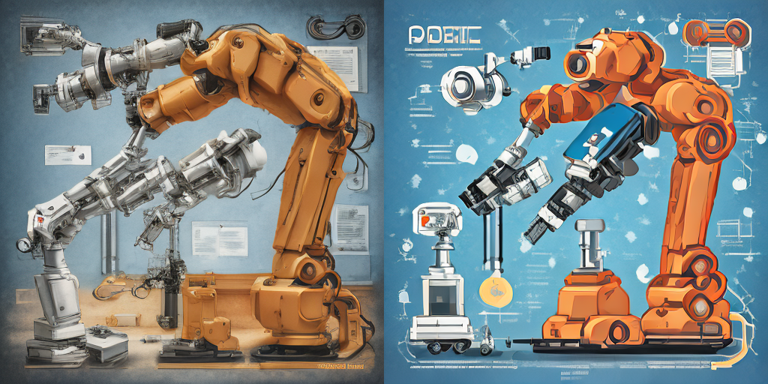

In [8]:
# Демонстрационный вариант 1 и сверка с таблицей 6.3 и значениями по seed из методички.
DEMO_REFERENCE = {"clip_target": (12.10, 2.80, 16.71, 4.61), "clip_subject": (25.24, 1.78, 25.65, 0.40),
                  "edge": (0.0375, 0.0025, 0.0443, 0.0069), "contrast": (0.1808, 0.0056, 0.1734, -0.0073)}
DEMO_SEED_REFERENCE = {"A": [14.80, 10.40, 12.77, 14.37, 8.16], "B": [15.35, 14.01, 17.02, 19.00, 18.19]}
demo_rows, demo_per_seed, demo_images, demo_seconds = run_variant(1)
for row in demo_rows:
    ra, rs, rb, rd = DEMO_REFERENCE[row["metric"]]
    row.update(A_ref=ra, s_ref=rs, B_ref=rb, d_ref=rd, A_within_2s_ref=abs(row["A"] - ra) <= 2 * rs, B_within_2s_ref=abs(row["B"] - rb) <= 2 * rs)
demo_seed = {m: [float(v) for v in demo_per_seed[demo_per_seed["mode"] == m]["clip_target"]] for m in ("A", "B")}
demo_sheet = side_by_side(demo_images)
demo_sheet.save(artifacts / "demo" / "comparison_variant01.png")
demo_per_seed.to_csv(artifacts / "demo" / "per_seed_metrics_variant01.csv", index=False)
(artifacts / "demo" / "demo_variant01.json").write_text(json.dumps(
    {"variant": 1, "rows": demo_rows, "clip_target_by_seed": demo_seed, "clip_target_by_seed_reference": DEMO_SEED_REFERENCE,
     "seconds": round(demo_seconds, 1)}, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame(demo_rows).round(4))
print("clip_target по seed, A:", [round(v, 2) for v in demo_seed["A"]], "| методичка:", DEMO_SEED_REFERENCE["A"])
print("clip_target по seed, B:", [round(v, 2) for v in demo_seed["B"]], "| методичка:", DEMO_SEED_REFERENCE["B"])
display(demo_sheet.resize((768, 384)))

### Вариант 7

In [9]:
# Обязательный вызов методички: L.variant_summary(pipe, clip, 7) — пять seed, режимы A и B, 10 изображений.
metric_rows, per_seed_df, images, summary_seconds = run_variant(VARIANT)
per_seed_df.to_csv(artifacts / "per_seed_metrics.csv", index=False)
(artifacts / "metrics.json").write_text(json.dumps(
    {"variant": VARIANT, "context": CTX, "element": ELEM, "prompt_a": PROMPT_A, "prompt_b": PROMPT_B, "clip_target_text": TARGET_TEXT,
     "seeds": SEEDS, "rows": metric_rows, "summary_seconds": round(summary_seconds, 1)}, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame(metric_rows).round(4))
display(per_seed_df.round(4))

вариант 7: запрос A = 'podcast cover about the city'; запрос B = 'podcast cover about the city, minimal flat geometric style'
clip_target  A= 10.7278 s= 2.2324 B= 14.9375 d= +4.2097 |d|/s=  1.89 2s=нет
clip_subject A= 23.8564 s= 0.8380 B= 22.8040 d= -1.0525 |d|/s=  1.26 2s=нет
edge         A=  0.0607 s= 0.0054 B=  0.0675 d= +0.0069 |d|/s=  1.28 2s=нет
contrast     A=  0.1907 s= 0.0150 B=  0.2233 d= +0.0326 |d|/s=  2.17 2s=да
секунд на вариант: 831.2 | среднее время изображения, с: 69.8


,metric,A,s,B,d,ratio,sig_2s
0,clip_target,10.7278,2.2324,14.9375,4.2097,1.8858,False
1,clip_subject,23.8564,0.8380,22.8040,-1.0525,1.2560,False
2,edge,0.0607,0.0054,0.0675,0.0069,1.2797,False
3,contrast,0.1907,0.0150,0.2233,0.0326,2.1745,True


,mode,seed,clip_target,clip_subject,edge,contrast,seconds
0,A,101,14.6207,23.0952,0.0549,0.1918,66.9411
1,A,102,9.8188,25.2623,0.0568,0.2119,65.7611
2,A,103,10.5056,23.8976,0.0682,0.1707,66.7755
3,A,104,9.5582,23.4244,0.0637,0.1945,68.8622
4,A,105,9.1356,23.6027,0.0597,0.1846,65.7331
5,B,101,14.3891,22.1898,0.0632,0.2126,71.6079
6,B,102,16.7744,22.0834,0.0623,0.2318,80.6404
7,B,103,13.4165,24.3899,0.0916,0.2351,78.3141
8,B,104,15.4079,23.4092,0.0701,0.2299,67.1160
9,B,105,14.6995,21.9475,0.0504,0.2072,66.3401


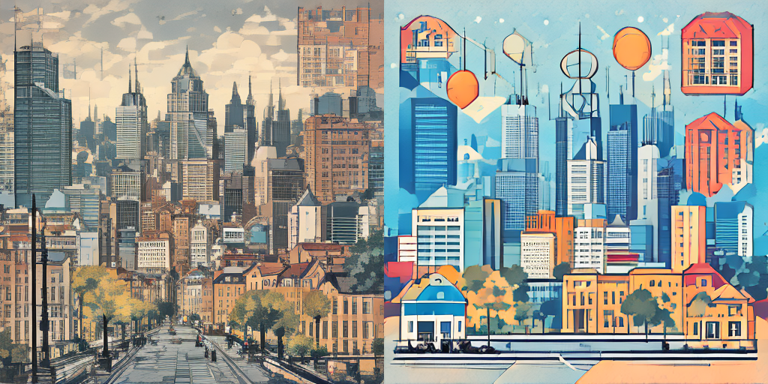

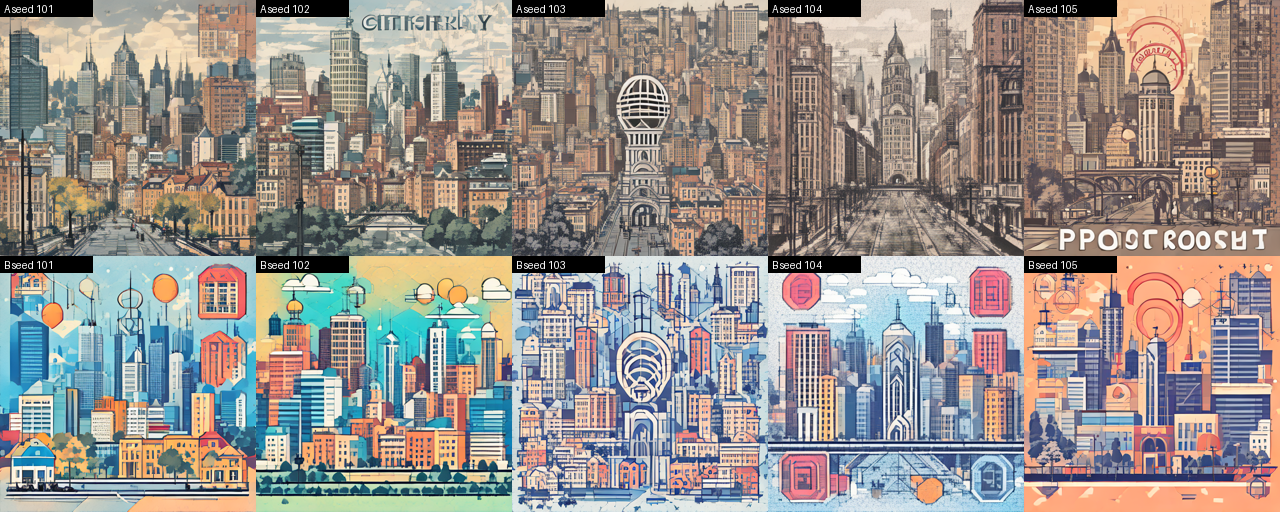

In [10]:
# Лист сравнения seed 101 (слева A, справа B) и лист всех пяти seed (верхний ряд A, нижний B).
comparison = side_by_side(images)
comparison.save(artifacts / "comparison.png")
tile = 256
seeds_sheet = Image.new("RGB", (tile * len(SEEDS), tile * 2), "white")
draw = ImageDraw.Draw(seeds_sheet)
for col, seed in enumerate(SEEDS):
    for row, mode in enumerate(("A", "B")):
        seeds_sheet.paste(images[(mode, seed)].resize((tile, tile)), (col * tile, row * tile))
        draw.rectangle([col * tile, row * tile, col * tile + 92, row * tile + 16], fill="black")
        draw.text((col * tile + 4, row * tile + 3), f"{mode} seed {seed}", fill="white")
seeds_sheet.save(artifacts / "comparison_all_seeds.png")
display(comparison.resize((768, 384)))
display(seeds_sheet)

In [11]:
# Классификация отклика (шаг 6 плана): значимо ли |Δ| > 2s и превосходит ли изменение допуск. Чувствительность к допуску: ×0.5 и ×2.
def over_tolerance(metric, a, d, scale=1.0):
    kind, tol = TOLERANCE[metric]
    change = d if kind == "abs" else d / a
    return abs(change) > tol * scale

classification = []
for r in metric_rows:
    kind, tol = TOLERANCE[r["metric"]]
    important = over_tolerance(r["metric"], r["A"], r["d"])
    label = {(True, True): "значимо и практически важно", (True, False): "только значимо",
             (False, True): "только практически важно", (False, False): "ни то ни другое"}[(r["sig_2s"], important)]
    classification.append({"metric": r["metric"], "change": r["d"] if kind == "abs" else r["d"] / r["A"], "change_kind": kind, "tolerance": tol,
                           "sig_2s": r["sig_2s"], "over_tolerance": important, "class": label,
                           "over_tolerance_x0_5": over_tolerance(r["metric"], r["A"], r["d"], 0.5),
                           "over_tolerance_x2": over_tolerance(r["metric"], r["A"], r["d"], 2.0)})
(artifacts / "classification.json").write_text(json.dumps({"variant": VARIANT, "rows": classification}, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(classification).round(4))

,metric,change,change_kind,tolerance,sig_2s,over_tolerance,class,over_tolerance_x0_5,over_tolerance_x2
0,clip_target,4.2097,abs,1.0,False,True,только практически важно,True,True
1,clip_subject,-1.0525,abs,1.0,False,True,только практически важно,True,False
2,edge,0.1131,rel,0.1,False,True,только практически важно,True,False
3,contrast,0.1711,rel,0.1,True,True,значимо и практически важно,True,False


In [12]:
# Намеренная ошибка 1: вывод по одному seed. Разность clip_target на каждом seed и соотношение с разбросом режима A.
a_t = per_seed_df[per_seed_df["mode"] == "A"].set_index("seed")["clip_target"]
b_t = per_seed_df[per_seed_df["mode"] == "B"].set_index("seed")["clip_target"]
seed_table = pd.DataFrame({"A": a_t, "B": b_t, "B − A": b_t - a_t}).round(2)
display(seed_table.T)
s_a = float(a_t.std(ddof=1))
one_seed_error = {
    "description": "conclusion about clip_target drawn from one seed only",
    "by_seed": {str(s): {"A": float(a_t[s]), "B": float(b_t[s]), "d": float(b_t[s] - a_t[s])} for s in SEEDS},
    "d_min": float((b_t - a_t).min()), "d_max": float((b_t - a_t).max()), "s_A": s_a,
    "d_seed_101_vs_2s": bool(abs(b_t[101] - a_t[101]) > 2 * s_a), "seeds_with_positive_d": int(((b_t - a_t) > 0).sum()),
    "fix": "five seeds, mean, s and the 2s criterion",
}
print(f"Δ по одному seed: от {one_seed_error['d_min']:+.2f} до {one_seed_error['d_max']:+.2f}; s режима A = {s_a:.2f}; Δ > 0 на {one_seed_error['seeds_with_positive_d']} seed из 5")

seed,101,102,103,104,105
A,14.62,9.82,10.51,9.56,9.14
B,14.39,16.77,13.42,15.41,14.70
B − A,-0.23,6.96,2.91,5.85,5.56


Δ по одному seed: от -0.23 до +6.96; s режима A = 2.23; Δ > 0 на 4 seed из 5


### Ручная визуальная проверка

Посмотрите на лист seed 101 и лист пяти seed. Читаются ли слои горизонта города как отдельные полосы? Отметьте, как изменился стиль, и артефакты: буквоподобные знаки, люди, узнаваемые здания. Образ не выдаётся за фотографию города.

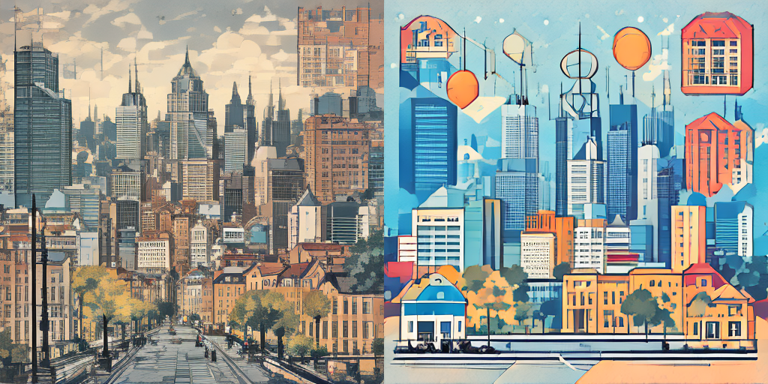

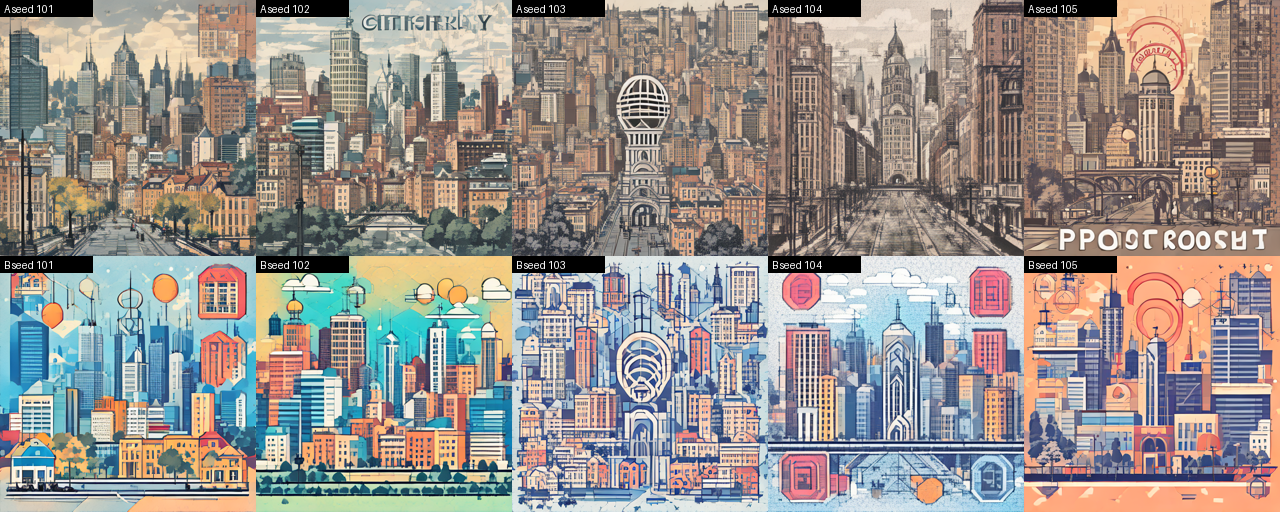

VISUAL_CHECK: {'a_bands_seed101': False, 'b_bands_seed101': True, 'seeds_a_bands': 0, 'seeds_b_bands': 4, 'notes': 'A: почти фотографические панорамы и улицы в перспективе, здания сливаются в плотную массу, отдельных полос нет ни на одном seed. B: плоская стилизованная иллюстрация с чёткими цветовыми блоками; ярусы горизонта читаются на seed 101, 102, 104 и 105, на seed 103 плотный узор с круглой эмблемой в центре. Стиль B не чистый минимализм: много мелких деталей, круглые фигуры и вывески. Артефакты: буквоподобные надписи на A seed 102 и A seed 105 и мелкие знаки внизу B seed 105, хотя текста в запросе не было. Изображения синтетические и не являются фотографией города.'}


In [29]:
display(comparison.resize((768, 384)))
display(seeds_sheet)

# Заполните только после фактического просмотра, затем перезапустите эту и последующие ячейки.
VISUAL_CHECK = {"a_bands_seed101": False, "b_bands_seed101": True, "seeds_a_bands": 0, "seeds_b_bands": 4, "notes": "A: почти фотографические панорамы и улицы в перспективе, здания сливаются в плотную массу, отдельных полос нет ни на одном seed. B: плоская стилизованная иллюстрация с чёткими цветовыми блоками; ярусы горизонта читаются на seed 101, 102, 104 и 105, на seed 103 плотный узор с круглой эмблемой в центре. Стиль B не чистый минимализм: много мелких деталей, круглые фигуры и вывески. Артефакты: буквоподобные надписи на A seed 102 и A seed 105 и мелкие знаки внизу B seed 105, хотя текста в запросе не было. Изображения синтетические и не являются фотографией города."}
visual_done = all(VISUAL_CHECK[key] is not None for key in ("a_bands_seed101", "b_bands_seed101", "seeds_a_bands", "seeds_b_bands")) and bool(VISUAL_CHECK["notes"])
print("VISUAL_CHECK:", VISUAL_CHECK if visual_done else "PENDING")

## Часть 2. Языковая модель: три приёма запроса

Запросы сформированы `lab09_llm.build_prompt` для контекста 2 и отправлены в новый чат на каждый повтор. Ячейки ниже записывают ответы без правок.

In [30]:
import os
os.makedirs("answers", exist_ok=True)
print("папка answers готова")

папка answers готова


In [31]:
%%writefile answers/ctx2_zero_r1.txt
```json
[
  {
    "subject": "Layered city skyline built from geometric shapes",
    "setting": "Square urban podcast cover",
    "style": "minimal geometric",
    "lighting": "Even soft light",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "Nighttime city skyline with glowing windows",
    "setting": "Rooftop viewpoint beneath a dark sky",
    "style": "photorealistic",
    "lighting": "Cool glowing window lights",
    "palette": ["blue", "black", "white"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "Bicycle lanes and public transit vehicles",
    "setting": "Bright urban streets",
    "style": "flat vector illustration",
    "lighting": "Bright daylight",
    "palette": ["blue", "green", "yellow"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "Urban courtyards and lush green rooftops",
    "setting": "Residential neighborhood viewed from above",
    "style": "flat vector illustration",
    "lighting": "Warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "Brick facades in a historic neighborhood",
    "setting": "Old district street",
    "style": "watercolor",
    "lighting": "Warm sunset light",
    "palette": ["red", "orange", "amber"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```


Overwriting answers/ctx2_zero_r1.txt


In [32]:
%%writefile answers/ctx2_zero_r2.txt
```json
[
  {
    "subject": "Layered city skyline built from geometric shapes",
    "setting": "Abstract urban background in square format",
    "style": "minimal geometric",
    "lighting": "Flat even lighting",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "Nighttime city skyline with glowing windows",
    "setting": "Rooftop viewpoint beneath a dark sky",
    "style": "photorealistic",
    "lighting": "Cool window glow",
    "palette": ["blue", "white", "black"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "Bicycle lanes and public transit vehicles",
    "setting": "Bright urban streets",
    "style": "flat vector illustration",
    "lighting": "Bright even daylight",
    "palette": ["blue", "green", "yellow"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "Urban courtyards and green rooftops",
    "setting": "Residential neighborhood viewed from above",
    "style": "flat vector illustration",
    "lighting": "Warm morning sunlight",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "Brick facades in an old neighborhood",
    "setting": "Historic neighborhood street",
    "style": "watercolor",
    "lighting": "Warm sunset light",
    "palette": ["red", "orange", "amber"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```


Overwriting answers/ctx2_zero_r2.txt


In [33]:
%%writefile answers/ctx2_zero_r3.txt
```json
[
  {
    "subject": "Layered city skyline built from geometric shapes",
    "setting": "Square podcast cover with a minimal background",
    "style": "minimal geometric",
    "lighting": "Even flat lighting",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "Nighttime city skyline with glowing windows",
    "setting": "Rooftop viewpoint beneath a dark sky",
    "style": "photorealistic",
    "lighting": "Cool glowing window lights",
    "palette": ["blue", "black", "white"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "Urban bicycle lanes and public transit",
    "setting": "City streets with dedicated cycling routes",
    "style": "flat vector illustration",
    "lighting": "Bright daylight",
    "palette": ["blue", "green", "yellow"],
    "composition": "wide negative space",
    "avoid": ["people"]
  },
  {
    "subject": "Urban courtyards and lush green rooftops",
    "setting": "Residential blocks viewed from directly above",
    "style": "flat vector illustration",
    "lighting": "Warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "Historic neighborhood buildings with brick facades",
    "setting": "Quiet street in an old district",
    "style": "watercolor",
    "lighting": "Warm sunset light",
    "palette": ["red", "orange", "amber"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```


Overwriting answers/ctx2_zero_r3.txt


In [34]:
%%writefile answers/ctx2_few_r1.txt
```json
[
  {
    "subject": "layered geometric city skyline in a square frame",
    "setting": "abstract urban background",
    "style": "minimal geometric",
    "lighting": "soft even light",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "nighttime city skyline with illuminated windows",
    "setting": "rooftop viewpoint beneath a dark sky",
    "style": "flat vector illustration",
    "lighting": "cool glowing window light",
    "palette": ["blue", "black", "white"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "bicycle lanes alongside buses and trams",
    "setting": "urban streets with public transport",
    "style": "flat vector illustration",
    "lighting": "bright daylight",
    "palette": ["blue", "green", "yellow"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "urban courtyards and lush green rooftops",
    "setting": "residential city blocks",
    "style": "flat vector illustration",
    "lighting": "warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "historic neighborhood buildings with brick facades",
    "setting": "old neighborhood street",
    "style": "watercolor",
    "lighting": "warm sunset light",
    "palette": ["red", "orange", "purple"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```


Overwriting answers/ctx2_few_r1.txt


In [35]:
%%writefile answers/ctx2_few_r2.txt
```json
[
  {
    "subject": "layered city skyline made of geometric shapes",
    "setting": "minimal urban backdrop",
    "style": "minimal geometric",
    "lighting": "soft even light",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "nighttime city skyline with illuminated windows",
    "setting": "rooftop viewpoint beneath a dark sky",
    "style": "photorealistic",
    "lighting": "cool window glow",
    "palette": ["blue", "black", "white"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "bicycle lanes and public transit vehicles",
    "setting": "bright city streets",
    "style": "flat vector illustration",
    "lighting": "bright daylight",
    "palette": ["blue", "yellow", "green"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "urban courtyards and buildings with green roofs",
    "setting": "residential city blocks",
    "style": "flat vector illustration",
    "lighting": "warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "brick facades in an old neighborhood",
    "setting": "historic neighborhood street at sunset",
    "style": "watercolor",
    "lighting": "warm sunset light",
    "palette": ["red", "orange", "purple"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```


Overwriting answers/ctx2_few_r2.txt


In [36]:
%%writefile answers/ctx2_few_r3.txt
```json
[
  {
    "subject": "layered city skyline built from geometric shapes",
    "setting": "abstract urban background within a square frame",
    "style": "minimal geometric",
    "lighting": "soft even light",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "nighttime city skyline with glowing windows",
    "setting": "rooftop viewpoint beneath a dark sky",
    "style": "photorealistic",
    "lighting": "cool glowing window light",
    "palette": ["blue", "black", "white"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "urban bicycle lanes buses and trams",
    "setting": "bright city streets with dedicated bicycle lanes",
    "style": "flat vector illustration",
    "lighting": "bright daylight",
    "palette": ["blue", "yellow", "green"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "urban courtyards and lush green rooftops",
    "setting": "residential blocks with planted roofs and courtyards",
    "style": "flat vector illustration",
    "lighting": "warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "historic neighborhood buildings with brick facades",
    "setting": "old neighborhood street at sunset",
    "style": "watercolor",
    "lighting": "warm sunset light",
    "palette": ["red", "orange", "purple"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```

Overwriting answers/ctx2_few_r3.txt


In [37]:
%%writefile answers/ctx2_step_r1.txt
```json
[
  {
    "subject": "Layered city skyline built from geometric shapes",
    "setting": "Square podcast cover",
    "style": "minimal geometric",
    "lighting": "Even diffuse light",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "Nighttime city skyline with glowing windows",
    "setting": "Rooftop view beneath a dark sky",
    "style": "photorealistic",
    "lighting": "Cool night with window lights",
    "palette": ["black", "blue", "white"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "Bicycle lanes and public transport",
    "setting": "City streets on a podcast cover",
    "style": "flat vector illustration",
    "lighting": "Bright daylight",
    "palette": ["blue", "yellow", "red"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "Urban courtyards and lush green rooftops",
    "setting": "Residential neighborhood viewed from above",
    "style": "flat vector illustration",
    "lighting": "Warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "Old neighborhood with brick building facades",
    "setting": "Historic neighborhood street",
    "style": "watercolor",
    "lighting": "Warm sunset light",
    "palette": ["red", "orange", "amber"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```

Overwriting answers/ctx2_step_r1.txt


In [38]:
%%writefile answers/ctx2_step_r2.txt
```json
[
  {
    "subject": "Layered city skyline built from geometric shapes",
    "setting": "Square podcast cover",
    "style": "minimal geometric",
    "lighting": "Soft even light",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "Nighttime city skyline with illuminated windows",
    "setting": "Rooftop viewpoint beneath a dark sky",
    "style": "photorealistic",
    "lighting": "Cool glowing window light",
    "palette": ["black", "blue", "white"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "Bicycle lanes and public transit vehicles",
    "setting": "Bright urban streets",
    "style": "flat vector illustration",
    "lighting": "Bright daylight",
    "palette": ["blue", "yellow", "red"],
    "composition": "wide negative space",
    "avoid": ["people"]
  },
  {
    "subject": "Urban courtyards and green rooftops",
    "setting": "Residential city blocks",
    "style": "flat vector illustration",
    "lighting": "Warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "Old neighborhood with brick facades",
    "setting": "Historic residential streets",
    "style": "watercolor",
    "lighting": "Warm sunset light",
    "palette": ["red", "orange", "amber"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```

Overwriting answers/ctx2_step_r2.txt


In [39]:
%%writefile answers/ctx2_step_r3.txt
Ключевые **элементы**:

1. Предмет: слоистый городской силуэт из геометрических фигур; стиль: минималистичная геометрия; цвета: бирюзовый и оранжевый; формат: квадратный; прямых запретов нет.
2. Предмет: ночной город с огнями окон, вид с крыши; стиль: фотореализм; цвета: синий, жёлтый и чёрный; ограничения: исключить оранжевый и янтарный.
3. Предмет: велодорожки и общественный транспорт; стиль: яркая плоская иллюстрация; цвета: синий, зелёный и жёлтый; ограничения: без людей.
4. Предмет: дворы и зелёные крыши, вид сверху; стиль: плоская иллюстрация; освещение: тёплое утро; цвета: ровно зелёный и жёлтый; прямых запретов нет.
5. Предмет: кирпичные фасады старого района; стиль: акварель; освещение: закатное; цвета: красный, оранжевый и янтарный; прямых запретов нет.

```json
[
  {
    "subject": "Layered city skyline built from geometric shapes",
    "setting": "Square podcast cover background",
    "style": "minimal geometric",
    "lighting": "Even soft lighting",
    "palette": ["teal", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "Nighttime city skyline with illuminated windows",
    "setting": "Rooftop viewpoint beneath a dark sky",
    "style": "photorealistic",
    "lighting": "Cool night with glowing windows",
    "palette": ["blue", "yellow", "black"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "Bicycle lanes and public transit vehicles",
    "setting": "Bright urban streets",
    "style": "flat vector illustration",
    "lighting": "Bright daylight",
    "palette": ["blue", "green", "yellow"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "Urban courtyards and lush green rooftops",
    "setting": "Residential city blocks",
    "style": "flat vector illustration",
    "lighting": "Warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "Old neighborhood buildings with brick facades",
    "setting": "Historic neighborhood street",
    "style": "watercolor",
    "lighting": "Warm sunset light",
    "palette": ["red", "orange", "amber"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```

Overwriting answers/ctx2_step_r3.txt


In [40]:
%%writefile answers/ctx2_error_old_prompt.txt
```json
[
  {
    "subject": "Layered city skyline built from geometric shapes",
    "setting": "Square podcast cover background",
    "style": "minimal geometric",
    "lighting": "Even diffuse lighting",
    "palette": ["turquoise", "orange"],
    "composition": "centered",
    "avoid": []
  },
  {
    "subject": "Nighttime city skyline with glowing windows",
    "setting": "Rooftop overlooking the city beneath a dark sky",
    "style": "photorealistic",
    "lighting": "Cool window lights at night",
    "palette": ["navy blue", "cool white", "cyan"],
    "composition": "rule of thirds",
    "avoid": []
  },
  {
    "subject": "Bicycle lanes and public transit vehicles",
    "setting": "Bright urban streets",
    "style": "flat vector illustration",
    "lighting": "Bright daylight",
    "palette": ["blue", "yellow", "green"],
    "composition": "rule of thirds",
    "avoid": ["people"]
  },
  {
    "subject": "Urban courtyards and green rooftops",
    "setting": "Residential city blocks",
    "style": "flat vector illustration",
    "lighting": "Warm morning light",
    "palette": ["green", "yellow"],
    "composition": "top-down",
    "avoid": []
  },
  {
    "subject": "Brick facades of an old neighborhood",
    "setting": "Historic neighborhood street",
    "style": "watercolor",
    "lighting": "Warm sunset light",
    "palette": ["brick red", "gold", "ochre"],
    "composition": "rule of thirds",
    "avoid": []
  }
]
```

Overwriting answers/ctx2_error_old_prompt.txt


In [41]:
# Сведения о языковой модели для паспорта: сервис, режим, как определялся режим, условия, дата.
LLM_INFO = {"service": "Perplexity, web version", "account": "free", "mode": "default mode, model not selected (model list is locked on the free plan)", "model": "unknown: the interface does not show the model name", "how_mode_was_determined": "from the model menu of the web interface", "conditions": "search disabled by the prompt text; every repeat in a new chat without history", "date": "06.11.2026"}
print("LLM_INFO:", LLM_INFO if LLM_INFO else "PENDING: ответы ещё не получены")

LLM_INFO: {'service': 'Perplexity, web version', 'account': 'free', 'mode': 'default mode, model not selected (model list is locked on the free plan)', 'model': 'unknown: the interface does not show the model name', 'how_mode_was_determined': 'from the model menu of the web interface', 'conditions': 'search disabled by the prompt text; every repeat in a new chat without history', 'date': '06.11.2026'}


In [42]:
# Оценка ответов: K1, K2, K3 по каждому файлу и K4 по приёму (функции lab09_llm без изменений).
APPROACHES = {"zero": "zero-shot", "few": "few-shot", "step": "пошаговые инструкции"}
answer_files = {a: [f"answers/ctx{CTX}_{a}_r{r}.txt" for r in (1, 2, 3)] for a in APPROACHES}
part2_done = all(pathlib.Path(p).is_file() for paths in answer_files.values() for p in paths)
part2 = {}
if part2_done:
    rows2, per_file = [], []
    for a, paths in answer_files.items():
        rs = [M.score_file(p, CTX) for p in paths]
        for p, r in zip(paths, rs):
            per_file.append({"file": p, "k1": r["k1"], "k2": r["k2"], "k3": r["k3"], "parsed": r["parsed"], "n": r["n"], "errors": r["errors"]})
        rows2.append({"approach": a, "name": APPROACHES[a], "k1": float(np.mean([r["k1"] for r in rs])), "k2": float(np.mean([r["k2"] for r in rs])),
                      "k3": float(np.mean([r["k3"] for r in rs])), "k4": M.stability(paths)})
    part2 = {"context": CTX, "rows": rows2, "per_file": per_file}
    err_path = pathlib.Path(f"answers/ctx{CTX}_error_old_prompt.txt")
    if err_path.is_file():
        e = M.score_file(str(err_path), CTX)
        part2["error_demo"] = {"file": str(err_path), "k1": e["k1"], "k2": e["k2"], "k3": e["k3"], "errors": e["errors"],
                               "diagnosis": "the prompt had no closed colour list, so the check measures a rule that was not requested"}
    shutil.copytree("answers", artifacts / "answers", dirs_exist_ok=True)
    (artifacts / "part2_scores.json").write_text(json.dumps(part2, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    display(pd.DataFrame(rows2).round(3))
    display(pd.DataFrame(per_file).drop(columns="errors").round(3))
    for row in per_file:
        if row["errors"]:
            print(row["file"], row["errors"])
    if "error_demo" in part2:
        print("Запрос без списка цветов:", {key: part2["error_demo"][key] for key in ("k1", "k2", "k3")}, part2["error_demo"]["errors"])
else:
    print("Часть 2: PENDING — файлов ответов ещё нет")

,approach,name,k1,k2,k3,k4
0,zero,zero-shot,1.0,1.0,1.0,0.933
1,few,few-shot,1.0,1.0,1.0,0.933
2,step,пошаговые инструкции,1.0,1.0,1.0,0.933


,file,k1,k2,k3,parsed,n
0,answers/ctx2_zero_r1.txt,1.0,1.0,1.0,True,5
1,answers/ctx2_zero_r2.txt,1.0,1.0,1.0,True,5
2,answers/ctx2_zero_r3.txt,1.0,1.0,1.0,True,5
3,answers/ctx2_few_r1.txt,1.0,1.0,1.0,True,5
4,answers/ctx2_few_r2.txt,1.0,1.0,1.0,True,5
5,answers/ctx2_few_r3.txt,1.0,1.0,1.0,True,5
6,answers/ctx2_step_r1.txt,1.0,1.0,1.0,True,5
7,answers/ctx2_step_r2.txt,1.0,1.0,1.0,True,5
8,answers/ctx2_step_r3.txt,1.0,1.0,1.0,True,5


Запрос без списка цветов: {'k1': 0.4, 'k2': 1.0, 'k3': 1.0} ['объект 1: palette: 1–3 цвета из списка', 'объект 2: palette: 1–3 цвета из списка', 'объект 5: palette: 1–3 цвета из списка']


In [43]:
# Паспорт эксперимента — все измеряемые поля берутся из этого сеанса.
complete = visual_done and part2_done and bool(LLM_INFO)
intentional_error = {"part_1_one_seed": one_seed_error, "part_2_rule_not_in_prompt": part2.get("error_demo")}
(artifacts / "intentional_error.json").write_text(json.dumps(intentional_error, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
experiment_passport = {
    "status": "COMPLETE" if complete else "PARTIAL",
    "variant": VARIANT, "context": CTX, "element": ELEM, "factor": L.FACTORS[k],
    "hypothesis_recorded_at": HYPOTHESIS_RECORDED_AT,
    "hypotheses": {
        "H1": "clip_target grows by more than 2s and more than 1.0", "H2": "clip_subject does not fall by more than 1.0",
        "H3": "edge grows by more than 10 %, contrast changes within ±10 %", "H4": "horizon layers read as bands on B more often than on A",
        "H5": "K1, K2, K3 are at least 0.8 for all approaches", "H6": "K4 is highest for few-shot and lowest for step-by-step",
    },
    "tolerance": {m: {"kind": kind, "value": tol} for m, (kind, tol) in TOLERANCE.items()},
    "part_1": {
        "model": {"model_id": L.MODEL_ID, "revision": L.REVISION}, "clip": {"model_id": L.CLIP_ID, "revision": L.CLIP_REVISION},
        "prompt_a": PROMPT_A, "prompt_b": PROMPT_B, "clip_target_text": TARGET_TEXT, "seeds": SEEDS,
        "parameters": {"steps": L.STEPS, "guidance_scale": L.GUIDANCE, "size": L.SIZE, "dtype": "float32", "device": "cpu", "generator_device": "cpu"},
        "metrics": metric_rows, "classification": classification, "visual_check": VISUAL_CHECK,
        "demo_reproduction": demo_rows,
    },
    "part_2": {"llm": LLM_INFO, "repeats": 3, "new_chat_per_repeat": True, **part2},
    "intentional_error": intentional_error,
    "environment": environment, "library_sha256": library_sha256,
    "timings_seconds": {"pipe_load": round(pipe_load_seconds, 1), "clip_load": round(clip_load_seconds, 1),
                        "demo_variant": round(demo_seconds, 1), "variant_summary": round(summary_seconds, 1),
                        "image_mean": round(float(per_seed_df["seconds"].mean()), 1)},
    "limitations": [
        "one run, one model, one context, one added element, five seeds; s is estimated from five values of mode A",
        "CLIP similarity measures text alignment, not quality",
        "library versions in Colab are newer than those checked in the methodology",
        "one language model service on one date; three repeats, 30 non-independent comparisons per approach",
    ],
    "license": "SD Turbo: Stability AI Community License Agreement, educational non-commercial use; CLIP: see model card at the pinned revision; synthetic prompts and customer descriptions",
    "executed_at_utc": datetime.now(timezone.utc).isoformat(),
}
(artifacts / "passport.json").write_text(json.dumps(experiment_passport, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
environment_lines = ["STATUS=ACTUAL", "execution_environment=Google Colab", "device=cpu", f"cuda_available={environment['cuda_available']}",
                     f"python={environment['python']}", *[f"{name}={version}" for name, version in environment["packages"].items()],
                     f"platform={environment['platform']}", *[f"environment_fix={fix}" for fix in ENVIRONMENT_FIXES],
                     f"model={L.MODEL_ID}@{L.REVISION}", f"clip={L.CLIP_ID}@{L.CLIP_REVISION}"]
(reports / "environment.txt").write_text("\n".join(environment_lines) + "\n", encoding="utf-8")
print(json.dumps({key: experiment_passport[key] for key in ("status", "timings_seconds")}, ensure_ascii=False, indent=2))

{
  "status": "COMPLETE",
  "timings_seconds": {
    "pipe_load": 61.4,
    "clip_load": 25.5,
    "demo_variant": 858.1,
    "variant_summary": 831.2,
    "image_mean": 69.8
  }
}


In [44]:
# Итоговая проверка файлов, JSON, PNG и чек-листа методички.
required_files = [
    artifacts / "metrics.json", artifacts / "per_seed_metrics.csv", artifacts / "classification.json", artifacts / "comparison.png",
    artifacts / "comparison_all_seeds.png", artifacts / "intentional_error.json", artifacts / "part2_scores.json",
    artifacts / "demo" / "demo_variant01.json", artifacts / "demo" / "comparison_variant01.png",
    artifacts / "demo" / "per_seed_metrics_variant01.csv", artifacts / "passport.json", reports / "environment.txt",
]
assert part2_done, "Нет девяти файлов ответов языковой модели"
assert bool(LLM_INFO), "Нет сведений о языковой модели для паспорта"
assert visual_done, "Заполните VISUAL_CHECK после фактического просмотра"
for path in required_files:
    assert path.is_file() and path.stat().st_size > 0, f"Missing or empty: {path}"
    if path.suffix == ".json":
        json.loads(path.read_text(encoding="utf-8"))
for path in (artifacts / "comparison.png", artifacts / "demo" / "comparison_variant01.png"):
    with Image.open(path) as check_image:
        check_image.verify()
    with Image.open(path) as check_image:
        assert check_image.format == "PNG" and check_image.size == (1024, 512), (path, check_image.size)
assert experiment_passport["status"] == "COMPLETE"

checklist = {
    "hypotheses_and_tolerance_before_run": True,
    "one_prompt_element_changed": PROMPT_B == PROMPT_A + ", " + L.ELEMENTS[c][k][0],
    "five_seed_series": len(per_seed_df) == 2 * len(SEEDS),
    "images_described": visual_done,
    "nine_answer_files_saved": sum(len(v) for v in answer_files.values()) == 9 and part2_done,
    "k1_k4_reported": len(part2["rows"]) == 3,
    "passport_complete": experiment_passport["status"] == "COMPLETE",
    "libraries_match_archive_sha256": library_sha256 == EXPECTED_SHA256,
    "demo_variant_executed_and_compared": bool(demo_rows),
}
print(json.dumps(checklist, ensure_ascii=False, indent=2))
assert all(checklist.values())
print("FULL CHECKLIST: PASS")

{
  "hypotheses_and_tolerance_before_run": true,
  "one_prompt_element_changed": true,
  "five_seed_series": true,
  "images_described": true,
  "nine_answer_files_saved": true,
  "k1_k4_reported": true,
  "passport_complete": true,
  "libraries_match_archive_sha256": true,
  "demo_variant_executed_and_compared": true
}
FULL CHECKLIST: PASS


In [45]:
# Архив результатов для переноса в репозиторий: artifacts/, reports/ и записанные библиотеки.
import zipfile
with zipfile.ZipFile("lab09_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted([*artifacts.rglob("*"), *reports.rglob("*")]):
        if path.is_file():
            archive.write(path)
    for name in EXPECTED_SHA256:
        archive.write(name)
print("lab09_results.zip:", round(pathlib.Path("lab09_results.zip").stat().st_size / 1024), "KiB")
try:
    from google.colab import files
    files.download("lab09_results.zip")
except ImportError:
    pass

lab09_results.zip: 3186 KiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>